# Лабораторная работа №3: оптимизация гиперпараметров

Продолжение лабораторной №1. Используем **Wine Quality** (красные и белые вина),
те же 12 признаков, удаление дубликатов и разбиение train/test.
Цель — предсказать `quality`, основная метрика — **RMSE: меньше — лучше**.

Подбираем три параметра **RandomForestRegressor** с помощью Grid Search и Random Search.
Baseline — итоговый случайный лес из лабы №1, а не константный прогноз:
`n_estimators=300`, `max_features=0.33`, `min_samples_leaf=1`, `max_depth=None`, `random_state=42`.
В лабе №1 он получил CV RMSE ≈ 0.6863 и Test RMSE ≈ 0.6798.
В этой работе заново проверим его на тех же данных.

In [ ]:
%pip install -q pandas numpy matplotlib seaborn "scikit-learn>=1.4"

In [2]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, KFold, cross_validate, train_test_split,
)

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
SCORING = "neg_root_mean_squared_error"

## 1. Данные и исходная модель

Данные берём из `regression/data/`, повторяя подготовку из лабы №1.
Пропусков нет. Масштабирование деревьям не нужно.
Точные дубликаты удаляем до разбиения, чтобы копии не попали в разные выборки.

In [3]:
ROOT = Path.cwd()
if not (ROOT / "regression").exists():
    ROOT = ROOT.parent

red = pd.read_csv(ROOT / "regression/data/winequality-red.csv", sep=";")
white = pd.read_csv(ROOT / "regression/data/winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0
df = pd.concat([red, white], ignore_index=True)
data = df.drop_duplicates().reset_index(drop=True)
X = data.drop(columns="quality")
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y,
)
print(f"Всего: {len(df)}, дубликатов удалено: {len(df) - len(data)}")
print(f"Пропусков: {data.isna().sum().sum()}")
print(f"Train: {X_train.shape}, test: {X_test.shape}")
display(X_train.head())

Всего: 6497, дубликатов удалено: 1177
Пропусков: 0
Train: (4256, 12), test: (1064, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
485,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,1
3185,6.6,0.250,0.42,11.3,0.049,77.0,231.0,0.99660,3.24,0.52,9.5,0
3540,7.4,0.200,0.37,1.2,0.028,28.0,89.0,0.99132,3.14,0.61,11.8,0
3023,7.6,0.160,0.41,1.9,0.047,27.0,151.0,0.99370,3.20,0.53,10.1,0
3643,6.9,0.160,0.37,1.8,0.034,36.0,95.0,0.98952,2.93,0.59,12.0,0


## 2. Кросс-валидация

Используем **5 folds**, как в лабе №1: на каждом шаге 80% train служит для обучения,
20% — для проверки. Это компромисс между временем и устойчивостью оценки.
`KFold(n_splits=5)` повторяет `cv=5` для регрессии из первой работы;
train уже перемешан при разбиении. Все модели проверяются на одних и тех же фолдах.

Кросс-валидация показывает, как качество меняется на разных частях обучающих данных.
Одного train/test недостаточно для подбора: если выбирать параметры по test,
он перестаёт быть независимой проверкой. При многократном выборе по test
мы подстраиваемся под его случайные особенности и получаем слишком оптимистичную оценку.

В sklearn поиск максимизирует метрику, поэтому используем **отрицательный RMSE**.
В таблицах меняем знак обратно и показываем обычную ошибку.

In [4]:
cv = KFold(n_splits=5)
baseline = RandomForestRegressor(
    n_estimators=300, max_features=0.33, min_samples_leaf=1,
    max_depth=None, random_state=RANDOM_STATE, n_jobs=1,
)
baseline_cv = cross_validate(
    baseline, X_train, y_train, cv=cv, scoring=SCORING,
    return_train_score=True, n_jobs=4,
)
baseline_folds = -baseline_cv["test_score"]
print(f"Baseline CV RMSE: {baseline_folds.mean():.4f} ± {baseline_folds.std():.4f}")
print("Параметры baseline:", baseline.get_params())

Baseline CV RMSE: 0.6863 ± 0.0093
Параметры baseline: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.33, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


## 3. Гиперпараметры

| Параметр | Смысл | Сетка Grid Search | Ожидаемое влияние |
|---|---|---|---|
| `max_depth` | Максимальная глубина дерева | `4, 12, None` | Малая глубина может недообучаться; большая описывает сложные связи, но может подгоняться под шум |
| `min_samples_leaf` | Минимум объектов в листе | `1, 5, 15` | Рост параметра сглаживает прогноз и ограничивает переобучение; слишком большое значение упрощает модель |
| `max_features` | Доля признаков, доступных при разбиении | `0.33, 1.0` | Меньшая доля делает деревья разнообразнее, но может лишать их полезных признаков; большая делает деревья более похожими |

Всего **3 × 3 × 2 = 18 комбинаций**. Сетка содержит параметры исходной модели.
Число деревьев оставляем равным 300, как в лабе №1, чтобы не увеличивать пространство поиска.

Для Random Search берём более подробные диапазоны тех же трёх параметров,
но проверяем тоже **18 комбинаций** и используем те же 5 folds.
Это одинаковый бюджет по числу обучений (90 на поиск плюс финальное обучение),
хотя время одной модели зависит от её глубины и числа доступных признаков.

In [5]:
param_grid = {
    "max_depth": [4, 12, None],
    "min_samples_leaf": [1, 5, 15],
    "max_features": [0.33, 1.0],
}
grid = GridSearchCV(
    baseline, param_grid, cv=cv, scoring=SCORING,
    return_train_score=True, n_jobs=4,
)
start = perf_counter()
grid.fit(X_train, y_train)
grid_time = perf_counter() - start
print("Grid Search — лучшие параметры:", grid.best_params_)
print(f"CV RMSE: {-grid.best_score_:.4f}")
print(f"Комбинаций: {len(grid.cv_results_['params'])}, время: {grid_time:.1f} с")

Grid Search — лучшие параметры: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1}
CV RMSE: 0.6863
Комбинаций: 18, время: 61.9 с


In [6]:
param_random = {
    "max_depth": [3, 5, 8, 12, 20, None],
    "min_samples_leaf": [1, 2, 3, 5, 10, 15],
    "max_features": [0.33, 0.5, 0.75, 1.0],
}
random = RandomizedSearchCV(
    baseline, param_random, n_iter=18, random_state=RANDOM_STATE,
    cv=cv, scoring=SCORING, return_train_score=True, n_jobs=4,
)
start = perf_counter()
random.fit(X_train, y_train)
random_time = perf_counter() - start
print("Random Search — лучшие параметры:", random.best_params_)
print(f"CV RMSE: {-random.best_score_:.4f}")
print(f"Комбинаций: {len(random.cv_results_['params'])}, время: {random_time:.1f} с")

Random Search — лучшие параметры: {'min_samples_leaf': 2, 'max_features': 0.33, 'max_depth': 20}
CV RMSE: 0.6891
Комбинаций: 18, время: 67.1 с


In [7]:
search_table = pd.DataFrame({
    "CV RMSE": [-grid.best_score_, -random.best_score_],
    "комбинаций": [len(grid.cv_results_["params"]), len(random.cv_results_["params"])],
    "обучений на CV": [18 * cv.n_splits, 18 * cv.n_splits],
    "время, с": [grid_time, random_time],
}, index=["Grid Search", "Random Search"])
display(search_table.round(4))

,CV RMSE,комбинаций,обучений на CV,"время, с"
Grid Search,0.6863,18,90,61.9264
Random Search,0.6891,18,90,67.1244


**Результат:** Grid Search выбрал исходные параметры: `max_depth=None`,
`max_features=0.33`, `min_samples_leaf=1`, CV RMSE **0.6863**.
Random Search выбрал `max_depth=20`, `max_features=0.33`, `min_samples_leaf=2`,
CV RMSE **0.6891**. Оба метода проверили 18 комбинаций и выполнили по 90 обучений на CV.
В этом запуске время составило **61.9 с** и **67.1 с** соответственно.

Random Search полезен при большом пространстве параметров и ограниченном времени:
не требуется проверять каждую комбинацию, а разные параметры исследуются на большем
числе значений. Он может пропустить удачную область, поэтому не гарантирует преимущество.
Здесь Grid Search проверил всю небольшую сетку, а Random Search — 18 из 144 комбинаций
более подробной сетки. Случайный поиск пропустил удачную исходную комбинацию
и оказался немного хуже. Одинаковое число обучений не гарантирует одинаковое время:
стоимость зависит от конкретных параметров. Время относится к этому компьютеру и запуску.

## 4. Влияние параметров

Используем уже полученные результаты Grid Search, без новых обучений.
На каждом графике меняем один параметр, остальные фиксируем на значениях,
выбранных Grid Search. Сравниваем средние ошибки на обучающих и проверочных фолдах.

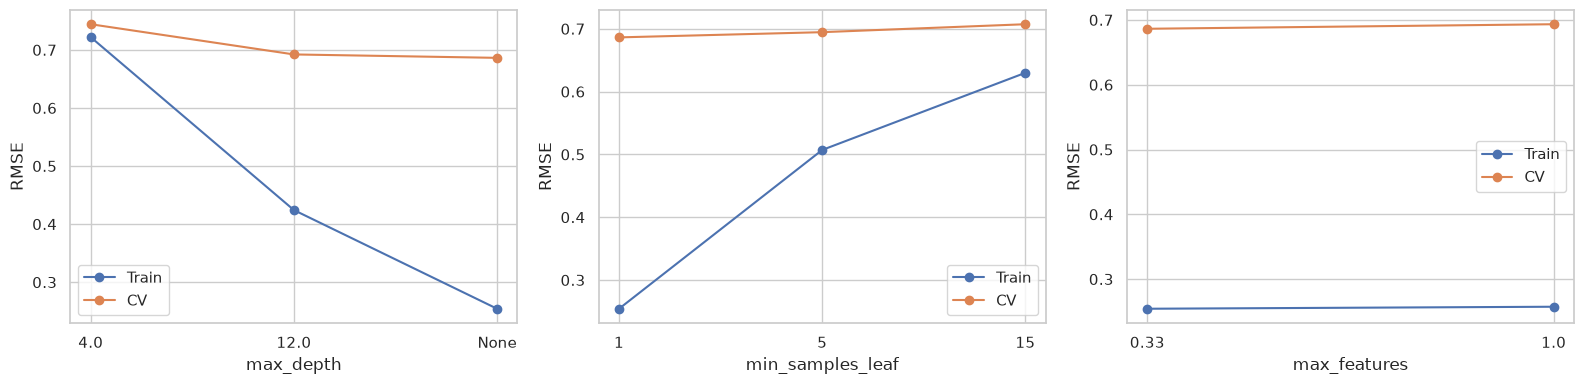

,max_depth,max_features,min_samples_leaf,Train RMSE,CV RMSE
0,4.0,0.33,1,0.7219,0.7442
1,4.0,0.33,5,0.7231,0.7439
2,4.0,0.33,15,0.7265,0.7450
3,4.0,1.00,1,0.7087,0.7363
4,4.0,1.00,5,0.7087,0.7346
5,4.0,1.00,15,0.7108,0.7346
6,12.0,0.33,1,0.4242,0.6922
7,12.0,0.33,5,0.5341,0.6961
8,12.0,0.33,15,0.6313,0.7076
9,12.0,1.00,1,0.3958,0.6965


In [8]:
grid_results = pd.DataFrame(grid.cv_results_["params"])
grid_results["max_depth"] = grid_results["max_depth"].fillna("None").astype(str)
grid_results["Train RMSE"] = -grid.cv_results_["mean_train_score"]
grid_results["CV RMSE"] = -grid.cv_results_["mean_test_score"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, parameter in zip(axes, param_grid):
    selected = grid_results.copy()
    for other, value in grid.best_params_.items():
        if other != parameter:
            if other == "max_depth":
                value = "None" if value is None else str(float(value))
            selected = selected[selected[other] == value]
    labels = [str(v) for v in selected[parameter]]
    positions = np.arange(len(selected))
    ax.plot(positions, selected["Train RMSE"], "o-", label="Train")
    ax.plot(positions, selected["CV RMSE"], "o-", label="CV")
    ax.set_xticks(positions, labels)
    ax.set_xlabel(parameter)
    ax.set_ylabel("RMSE")
    ax.legend()
plt.tight_layout()
plt.show()
display(grid_results.round(4))

**Вывод по графикам** (остальные параметры зафиксированы на лучших значениях Grid Search):

- **Недообучение:** при `max_depth=4` Train RMSE **0.722**, CV RMSE **0.744**.
  Обе ошибки высоки и близки: коротким деревьям не хватает сложности.
- **Увеличение глубины:** при глубине 12 CV RMSE **0.692**, без ограничения — **0.686**.
  В исследованной сетке разумный по CV вариант — глубокие деревья.
- **Размер листа:** при `min_samples_leaf=1, 5, 15` CV RMSE составляет
  **0.686, 0.695, 0.707**. Усиление ограничения здесь убирает полезные детали.
- **Доля признаков:** `max_features=0.33` даёт CV RMSE **0.686**,
  а `1.0` — **0.693**. Случайный выбор меньшего числа признаков помогает разнообразию деревьев.

При неограниченной глубине и листе из одного объекта Train RMSE **0.254**
существенно ниже CV RMSE **0.686**: модель сильно подгоняется под обучающие объекты.
Однако роста CV ошибки с глубиной не наблюдаем. Поэтому область вредного переобучения,
где дальнейшее усложнение ухудшает CV, в этой сетке не выявлена.
Большой разрыв train–CV сам по себе не делает более простой лес лучшим.

## 5. Устойчивость на отдельных folds

Берём ошибки каждого фолда для baseline и лучших комбинаций обоих поисков.
Среднее само по себе не показывает устойчивость: при одинаковом среднем
предпочтительнее небольшой разброс и отсутствие особенно неудачных фолдов.
Разброс зависит и от модели, и от состава фолдов; это не доверительный интервал.

,Baseline,Grid Search,Random Search
fold 1,0.6962,0.6962,0.6989
fold 2,0.6792,0.6792,0.6844
fold 3,0.6899,0.6899,0.6913
fold 4,0.6720,0.6720,0.6748
fold 5,0.6943,0.6943,0.6960


,среднее,std,минимум,максимум
Baseline,0.6863,0.0093,0.6720,0.6962
Grid Search,0.6863,0.0093,0.6720,0.6962
Random Search,0.6891,0.0087,0.6748,0.6989


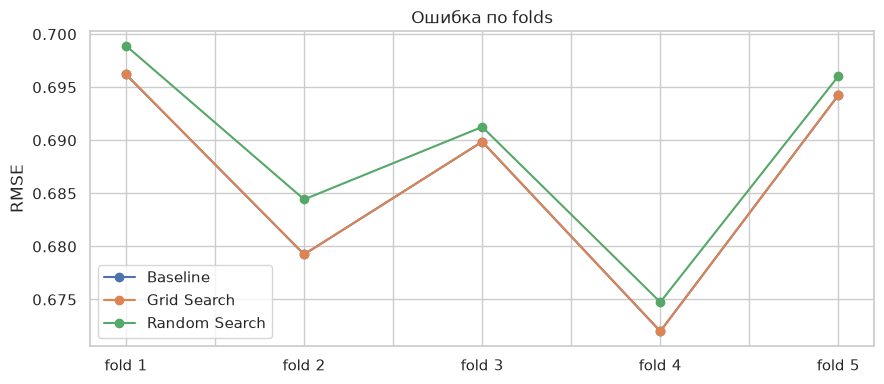

In [9]:
folds = pd.DataFrame({
    "Baseline": baseline_folds,
    "Grid Search": [-grid.cv_results_[f"split{i}_test_score"][grid.best_index_]
                    for i in range(cv.n_splits)],
    "Random Search": [-random.cv_results_[f"split{i}_test_score"][random.best_index_]
                      for i in range(cv.n_splits)],
}, index=[f"fold {i + 1}" for i in range(cv.n_splits)])
display(folds.round(4))
stability = pd.DataFrame({
    "среднее": folds.mean(), "std": folds.std(ddof=0),
    "минимум": folds.min(), "максимум": folds.max(),
})
display(stability.round(4))
folds.plot(marker="o", figsize=(9, 4), ylabel="RMSE", title="Ошибка по folds")
plt.tight_layout()
plt.show()

## 6. Финальные модели и test

Все решения уже приняты по CV. Выбираем победителя по минимальному CV RMSE
и больше не меняем параметры. Затем обучаем все три модели на полном train
и оцениваем на одном и том же test, как требует задание.
Сравнение на test не используется для повторного выбора модели.

Этот test уже оценивался в лабе №1, поэтому здесь это повторная проверка на знакомом
разбиении, а не новый независимый тест. Новые параметры подбираем только по CV.

In [10]:
models = {
    "Baseline": baseline,
    "Grid Search": grid.best_estimator_,
    "Random Search": random.best_estimator_,
}
chosen_name = folds.mean().idxmin()
print("Модель, выбранная по CV:", chosen_name)

rows = []
for name, model in models.items():
    fitted = clone(model).fit(X_train, y_train)
    rows.append({
        "модель": name,
        "CV RMSE": folds[name].mean(),
        "CV std": folds[name].std(ddof=0),
        "Test RMSE": root_mean_squared_error(y_test, fitted.predict(X_test)),
    })
final_table = pd.DataFrame(rows).set_index("модель")
final_table["улучшение CV, %"] = (
    1 - final_table["CV RMSE"] / final_table.loc["Baseline", "CV RMSE"]
) * 100
final_table["улучшение test, %"] = (
    1 - final_table["Test RMSE"] / final_table.loc["Baseline", "Test RMSE"]
) * 100
display(final_table.round(4))

Модель, выбранная по CV: Baseline


,CV RMSE,CV std,Test RMSE,"улучшение CV, %","улучшение test, %"
модель,,,,,
Baseline,0.6863,0.0093,0.6798,0.0000,0.0000
Grid Search,0.6863,0.0093,0.6798,0.0000,0.0000
Random Search,0.6891,0.0087,0.6795,-0.4026,0.0483


## 7. Итоги

- **Baseline и Grid Search совпали:** CV RMSE **0.6863**, Test RMSE **0.6798**.
  Улучшение — **0%**: исходный лес уже был подобран в лабе №1,
  а новые проверенные комбинации его не превзошли.
- **Random Search:** CV RMSE **0.6891** (примерно на 0.4% хуже),
  Test RMSE **0.6795** (примерно на 0.05% лучше). Улучшение на CV и test не совпало:
  эти выборки различаются, а преимущество на test всего около **0.0003 RMSE**.
  Это не основание выбирать модель заново по test. По CV сохраняем baseline;
  лучшая модель Grid Search — тот же лес.
- **Устойчивость:** baseline и Grid Search дали ошибки фолдов **0.6720–0.6962**,
  std **0.0093**. У Random Search диапазон **0.6748–0.6989**, std **0.0087**.
  Разброс немного меньше, но средняя ошибка выше. Малое различие средних
  не доказывает устойчивого преимущества без дополнительных экспериментов.
- **Параметры:** мелкие деревья недообучаются; глубокие деревья и маленькие листья
  лучше по CV. Доля признаков 0.33 оказалась лучше использования всех признаков.
  Ухудшения CV при увеличении глубины в проверенной сетке не обнаружили.
- Оба поиска использовали одинаковый бюджет: **18 комбинаций × 5 folds**.
  Все параметры выбраны только по train/CV, а test использован для итогового сравнения.
  Это тот же test, что в лабе №1, поэтому его нельзя считать новой независимой проверкой.